# 🔍 10. Comparación de los métodos de optimización

Este capítulo responde: **¿qué método de búsqueda de hiperparámetros conviene, y por qué?** Se usan dos fuentes:

1. El **experimento principal**: 140 combinaciones, cada búsqueda con 16 evaluaciones, dentro de la validación anidada (cap. 9).
2. Un **estudio aparte con más presupuesto** (`estudio_optimizadores.py`): XGBoost en las dos tareas, 60 evaluaciones por búsqueda y 3 semillas por método, en el fold externo 4. Sirve para ver la convergencia, la diversidad del genético y la estabilidad ante semillas, cosas que con 16 evaluaciones apenas se notan.

Todas las métricas de calidad son del **bucle externo** (o de la semana de validación externa del fold 4 en el estudio), nunca el mejor valor interno.

In [1]:
import json
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from comun import estilo, DATA, SEED, AZUL, NARANJA, VERDE, AMARILLO, GRIS, PALETA
from experimentos import armar_maestra, cargar, combinaciones
from estadistica import friedman_nemenyi, diagrama_cd, holm

estilo()
maestra = armar_maestra()
COLOR = {"grid": GRIS, "random": AZUL, "bayes": NARANJA, "genetico": VERDE}
NOMBRE = {"grid": "Grid", "random": "Random", "bayes": "Bayes (TPE)", "genetico": "Genético"}
# métrica principal de cada tarea, expresada como pérdida (menor es mejor)
maestra["perdida_media"] = np.where(maestra["tarea"] == "reg", maestra["rmse_log_media"], 1 - maestra["f1_media"])
print(f"{len(maestra)} combinaciones en la tabla maestra "
      f"({(maestra['tarea'] == 'reg').sum()} de regresión, {(maestra['tarea'] == 'clf').sum()} de clasificación)")
print(f"evaluaciones totales: {maestra['n_evals'].sum():,} (cada una = 3 ajustes) | "
      f"tiempo de cómputo sumado: {maestra['seg_total'].sum() / 3600:.1f} h")

140 combinaciones en la tabla maestra (28 de regresión, 112 de clasificación)
evaluaciones totales: 11,100 (cada una = 3 ajustes) | tiempo de cómputo sumado: 6.9 h


/opt/miniconda3/envs/ml_venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 📋 10.1 La tabla maestra

Cada fila es una combinación. Se muestran las columnas principales; el archivo completo (`resultados/maestra.csv`) tiene todas las métricas del bucle externo (media y desviación), las de test, los tiempos y los hiperparámetros finales.

In [2]:
cols = ["tarea", "modelo", "balanceo", "optimizador", "n_evals", "rmse_log_media", "rmse_log_desv",
        "f1_media", "f1_desv", "auc_media", "seg_total", "seg_por_eval", "params_final"]
# las 5 mejores de cada tarea según la métrica del bucle externo
pd.concat([maestra[maestra["tarea"] == t].nsmallest(5, "perdida_media")[cols] for t in ["reg", "clf"]])

,tarea,modelo,balanceo,optimizador,n_evals,rmse_log_media,rmse_log_desv,f1_media,f1_desv,auc_media,seg_total,seg_por_eval,params_final
16,reg,rf,ninguno,grid,80,0.89,0.13,NaN,NaN,NaN,446.71,4.53,"{""max_depth"": 16, ""max_features"": 0.6, ""min_sa..."
17,reg,rf,ninguno,random,80,0.89,0.13,NaN,NaN,NaN,386.72,4.05,"{""n_estimators"": 63, ""max_depth"": 12, ""min_sam..."
21,reg,xgb,ninguno,random,80,0.89,0.12,NaN,NaN,NaN,134.88,1.60,"{""n_estimators"": 373, ""learning_rate"": 0.01608..."
18,reg,rf,ninguno,bayes,80,0.89,0.12,NaN,NaN,NaN,539.90,5.35,"{""n_estimators"": 110, ""max_depth"": 16, ""min_sa..."
23,reg,xgb,ninguno,genetico,80,0.90,0.13,NaN,NaN,NaN,168.22,1.90,"{""n_estimators"": 434, ""learning_rate"": 0.01142..."
122,clf,xgb,balanced,bayes,80,NaN,NaN,0.29,0.07,0.86,155.93,1.78,"{""n_estimators"": 381, ""learning_rate"": 0.11082..."
120,clf,xgb,balanced,grid,80,NaN,NaN,0.29,0.07,0.85,153.14,1.73,"{""learning_rate"": 0.03, ""max_depth"": 8, ""n_est..."
121,clf,xgb,balanced,random,80,NaN,NaN,0.28,0.07,0.85,137.83,1.55,"{""n_estimators"": 382, ""learning_rate"": 0.14230..."
107,clf,rf,balanced,genetico,80,NaN,NaN,0.27,0.04,0.86,347.67,3.78,"{""n_estimators"": 119, ""max_depth"": 15, ""min_sa..."
123,clf,xgb,balanced,genetico,80,NaN,NaN,0.27,0.06,0.85,185.27,2.19,"{""n_estimators"": 423, ""learning_rate"": 0.11964..."


## ⚖️ 10.2 ¿Algún optimizador encuentra mejores modelos?

Para comparar optimizadores de forma justa, cada **bloque** es una misma configuración (modelo en regresión; modelo × balanceo en clasificación) y dentro de cada bloque se ordenan los 4 optimizadores por la métrica del bucle externo. Si un método fuera mejor, tendría consistentemente el rango 1. Se aplica la prueba de **Friedman** sobre esos rangos.

In [3]:
resumen, pruebas = [], []
for tarea, bloque in [("reg", ["modelo"]), ("clf", ["modelo", "balanceo"])]:
    sub = maestra[maestra["tarea"] == tarea]
    tabla = sub.pivot_table(index=bloque, columns="optimizador", values="perdida_media")
    fn = friedman_nemenyi(tabla)
    pruebas.append({"tarea": tarea, "bloques": fn["n"], "chi² Friedman": fn["chi2"], "p": fn["p"], "CD Nemenyi": fn["cd"]})
    for o in tabla:
        resumen.append({"tarea": tarea, "optimizador": NOMBRE[o], "rango medio": fn["rangos"][o],
                        "veces el mejor": int((tabla.idxmin(axis=1) == o).sum()),
                        "pérdida media": tabla[o].mean(),
                        "seg por evaluación": sub.loc[sub["optimizador"] == o, "seg_por_eval"].mean(),
                        "min por combinación": sub.loc[sub["optimizador"] == o, "seg_total"].mean() / 60})
display(pd.DataFrame(pruebas).set_index("tarea").round(4))
pd.DataFrame(resumen).set_index(["tarea", "optimizador"]).round(4)

,bloques,chi² Friedman,p,CD Nemenyi
tarea,,,,
reg,7,0.94,0.82,1.77
clf,28,5.38,0.15,0.89


rango medio  veces el mejor  pérdida media  \
tarea optimizador                                               
reg   Bayes (TPE)         2.29               2           0.94   
      Genético            2.29               2           0.94   
      Grid                2.57               2           0.94   
      Random              2.86               1           0.94   
clf   Bayes (TPE)         2.38               5           0.79   
      Genético            2.68               7           0.79   
      Grid                2.84               5           0.79   
      Random              2.11              11           0.79   

                   seg por evaluación  min por combinación  
tarea optimizador                                           
reg   Bayes (TPE)                1.28                 2.05  
      Genético                   1.04                 1.67  
      Grid                       1.24                 1.92  
      Random                     1.01                 1.55  
clf   Bayes (TPE)                2.21                 3.42  
      Genético                   2.14                 3.22  
      Grid                       2.09                 3.17  
      Random                     2.07                 3.15

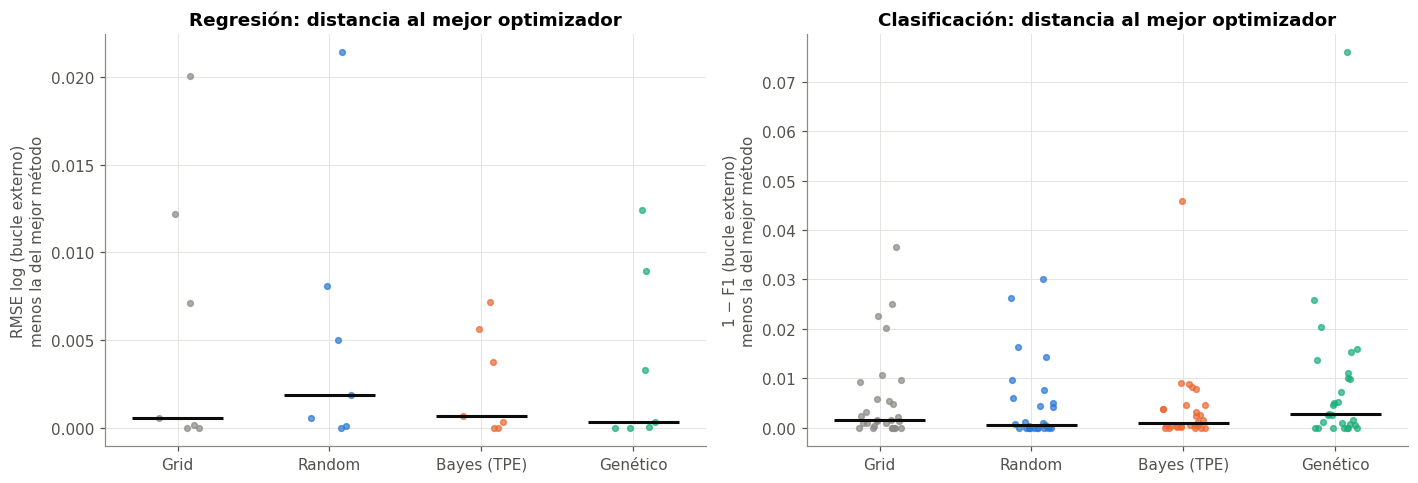

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for i, (tarea, etiqueta) in enumerate([("reg", "RMSE log (bucle externo)"), ("clf", "1 − F1 (bucle externo)")]):
    sub = maestra[maestra["tarea"] == tarea].copy()
    sub["config"] = sub["modelo"] + np.where(tarea == "clf", "·" + sub["balanceo"], "")
    tabla = sub.pivot_table(index="config", columns="optimizador", values="perdida_media")
    # diferencia contra el mejor optimizador de cada configuración (0 = fue el mejor)
    rel = tabla.sub(tabla.min(axis=1), axis=0)
    for j, o in enumerate(["grid", "random", "bayes", "genetico"]):
        x = np.full(len(rel), j) + np.random.default_rng(SEED).uniform(-0.15, 0.15, len(rel))
        ax[i].scatter(x, rel[o], s=14, color=COLOR[o], alpha=0.7)
        ax[i].hlines(rel[o].median(), j - 0.3, j + 0.3, color="#0b0b0b", lw=2)
    ax[i].set_xticks(range(4)); ax[i].set_xticklabels([NOMBRE[o] for o in ["grid", "random", "bayes", "genetico"]])
    ax[i].set_ylabel(f"{etiqueta}\nmenos la del mejor método")
    ax[i].set_title(f"{'Regresión' if tarea == 'reg' else 'Clasificación'}: distancia al mejor optimizador")
plt.tight_layout()

### Interpretación

- **En el experimento principal ningún optimizador es significativamente mejor.** Friedman no rechaza ni en regresión (p = 0,82, 7 bloques) ni en clasificación (p = 0,15, 28 bloques). La pérdida media es prácticamente la misma con los 4 métodos (0,94 en regresión y 0,79 en clasificación) y los puntos de la figura se concentran cerca de 0.
- Hay tres razones, y las tres son parte del resultado:
  1. **Con 16 evaluaciones los métodos inteligentes casi no alcanzan a aprender.** El TPE dedica 5 a explorar al azar y el genético solo hace 2 generaciones.
  2. **La mayoría de los modelos tiene 1 o 2 hiperparámetros** (Ridge, Lasso, NB, SVM, SVR, árbol, KNN). En un espacio de 1 dimensión una rejilla de 16 puntos ya lo cubre bien y no hay nada que "aprender".
  3. **La superficie de pérdida es plana** cerca del óptimo, como se vio con el SVR en la entrega 1: muchas configuraciones son casi igual de buenas.
- El **costo por evaluación** es parecido entre métodos (1,0–1,3 s en regresión y 2,1–2,2 s en clasificación). La sobrecarga del TPE (ajustar sus densidades) es despreciable frente a entrenar un modelo. Que Bayes y Grid tarden un poco más se explica por **las configuraciones que eligen** (más árboles o más profundos), no por el algoritmo de búsqueda.

## 📈 10.3 Convergencia en el experimento principal (*anytime performance*)

Para cada búsqueda se guardó la pérdida de cada evaluación. La curva *anytime* es el **mejor valor encontrado hasta la evaluación $t$**. Como las pérdidas de modelos distintos no son comparables, se normalizan: para cada (combinación, fold) se resta la mejor pérdida que encontró **cualquiera** de los 4 métodos en ese mismo problema y se divide por el rango. Así 0 = el mejor valor encontrado por alguien y 1 = el peor punto evaluado. La curva promedio es el **arrepentimiento normalizado** (*normalized regret*).

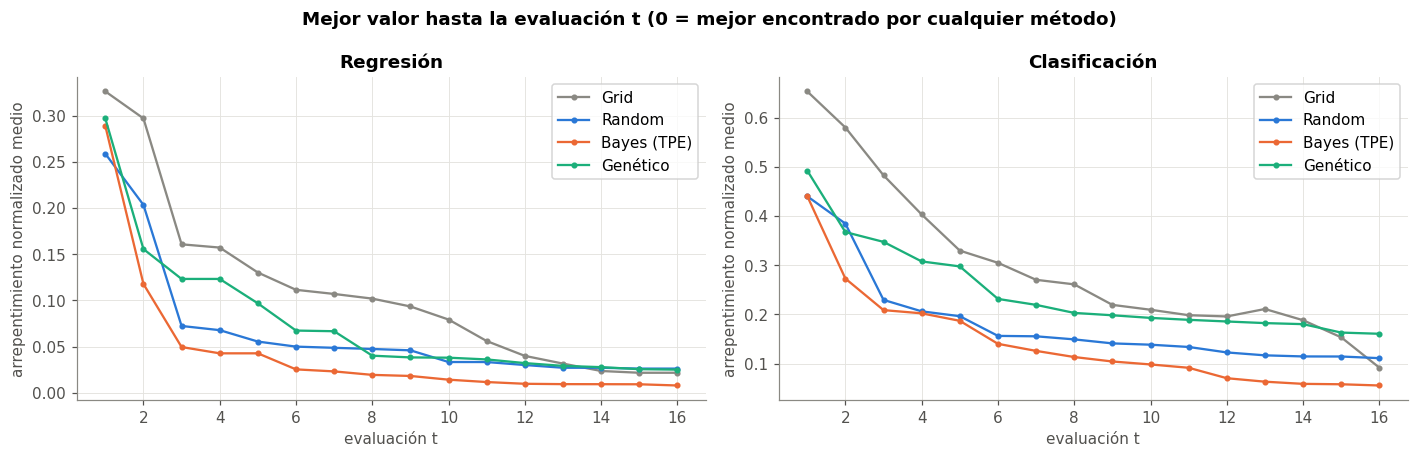

In [5]:
curvas = []
for tarea, modelo, balanceo, metodo in combinaciones():
    r = cargar(tarea, modelo, balanceo, metodo)
    for f in r["folds"] + [{"fold": "final", "historial": r["historial_final"]}]:
        h = pd.DataFrame(f["historial"])
        h = h[np.isfinite(h["perdida"])]
        curvas.append(pd.DataFrame({"tarea": tarea, "problema": f"{modelo}·{balanceo}·{f['fold']}", "optimizador": metodo,
                                    "eval": h["eval"], "perdida": h["perdida"], "mejor": h["perdida"].cummin(),
                                    "seg": h["seg"].cumsum()}))
curvas = pd.concat(curvas, ignore_index=True)
ref = curvas.groupby(["tarea", "problema"])["perdida"].agg(["min", "max"])
curvas = curvas.join(ref, on=["tarea", "problema"])
curvas["regret"] = (curvas["mejor"] - curvas["min"]) / (curvas["max"] - curvas["min"]).replace(0, np.nan)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
anytime = curvas.groupby(["tarea", "optimizador", "eval"])["regret"].mean().reset_index()
for i, tarea in enumerate(["reg", "clf"]):
    for o in ["grid", "random", "bayes", "genetico"]:
        c = anytime[(anytime["tarea"] == tarea) & (anytime["optimizador"] == o)]
        ax[i].plot(c["eval"], c["regret"], marker="o", ms=3, color=COLOR[o], label=NOMBRE[o])
    ax[i].set_xlabel("evaluación t"); ax[i].set_ylabel("arrepentimiento normalizado medio")
    ax[i].set_title("Regresión" if tarea == "reg" else "Clasificación"); ax[i].legend()
plt.suptitle("Mejor valor hasta la evaluación t (0 = mejor encontrado por cualquier método)", fontweight="bold")
plt.tight_layout()

In [6]:
# resumen cuantitativo: área bajo la curva de arrepentimiento (menor = converge antes) y
# % de problemas en los que el método llega al 1 % del mejor valor conocido
final = curvas.sort_values("eval").groupby(["tarea", "problema", "optimizador"]).tail(1)
filas = []
for (tarea, o), g in curvas.groupby(["tarea", "optimizador"]):
    area = g.groupby("problema")["regret"].mean()
    fin = final[(final["tarea"] == tarea) & (final["optimizador"] == o)]
    llega = (fin["mejor"] <= fin["min"] + 0.01 * (fin["max"] - fin["min"]))
    t_eval = g.groupby("problema")["seg"].max() / g.groupby("problema")["eval"].max()
    filas.append({"tarea": tarea, "optimizador": NOMBRE[o], "área bajo el regret (media)": area.mean(),
                  "regret final (media)": fin["regret"].mean(), "% de problemas en el mejor (±1 %)": llega.mean() * 100,
                  "seg por evaluación (mediana)": t_eval.median()})
pd.DataFrame(filas).set_index(["tarea", "optimizador"]).round(3)

área bajo el regret (media)  regret final (media)  \
tarea optimizador                                                      
clf   Bayes (TPE)                         0.14                  0.06   
      Genético                            0.24                  0.16   
      Grid                                0.29                  0.09   
      Random                              0.18                  0.11   
reg   Bayes (TPE)                         0.04                  0.01   
      Genético                            0.08                  0.03   
      Grid                                0.11                  0.02   
      Random                              0.07                  0.03   

                   % de problemas en el mejor (±1 %)  \
tarea optimizador                                      
clf   Bayes (TPE)                              60.71   
      Genético                                 28.57   
      Grid                                     35.00   
      Random                                   30.00   
reg   Bayes (TPE)                              74.29   
      Genético                                 54.29   
      Grid                                     57.14   
      Random                                   45.71   

                   seg por evaluación (mediana)  
tarea optimizador                                
clf   Bayes (TPE)                          0.66  
      Genético                             0.73  
      Grid                                 0.61  
      Random                               0.67  
reg   Bayes (TPE)                          0.45  
      Genético                             0.41  
      Grid                                 0.44  
      Random                               0.40

### Interpretación: la diferencia está en la velocidad de convergencia

Aunque la calidad final es parecida, **el TPE llega antes y más seguido a lo mejor**. Esta es la evidencia cuantitativa de eficiencia que pide la guía:

| | Bayes (TPE) | Random | Genético | Grid |
|---|---|---|---|---|
| Área bajo el *regret*, regresión (menor = converge antes) | **0,04** | 0,07 | 0,08 | 0,11 |
| Área bajo el *regret*, clasificación | **0,14** | 0,18 | 0,24 | 0,29 |
| % de problemas en que llega al mejor valor conocido (±1 %), regresión | **74 %** | 46 % | 54 % | 57 % |
| Ídem, clasificación | **61 %** | 30 % | 29 % | 35 % |

- Con el **mismo presupuesto y el mismo costo por evaluación**, el TPE acumula menos *regret* en todo el recorrido. Su curva baja más rápido después de las 5 evaluaciones iniciales al azar, que es justo cuando su modelo sustituto empieza a funcionar.
- **El Grid es el más lento:** recorre la rejilla en un orden fijo, que no tiene nada que ver con dónde está lo bueno, y en los modelos de 4–6 hiperparámetros solo prueba 2 valores por dimensión.
- **El genético** queda por detrás del aleatorio en clasificación. Con 16 evaluaciones (6 iniciales + 2 generaciones de 5), es casi una búsqueda aleatoria con un poco de refinamiento local, que a veces se concentra antes de tiempo.

## 🔬 10.4 Estudio con más presupuesto: 60 evaluaciones y 3 semillas

Con 16 evaluaciones los métodos inteligentes apenas tienen tiempo de aprender: el TPE usa 5 puntos al azar y le quedan 11; el genético alcanza a hacer 2 generaciones. Aquí se repite la búsqueda de **XGBoost** (6 hiperparámetros en Random/Bayes/Genético; rejilla de 60 puntos en 3 de ellos para el Grid) con **60 evaluaciones** y **3 semillas** (42, 7, 2026).

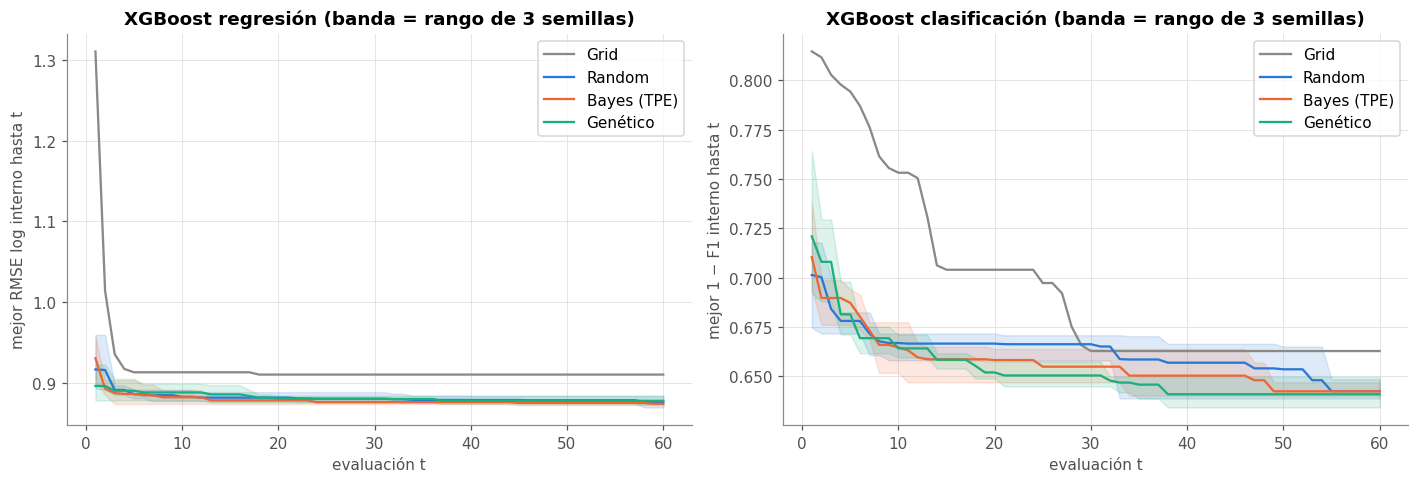

In [7]:
with open(DATA / "processed" / "estudio_optimizadores.pkl", "rb") as fh:
    estudio = pickle.load(fh)
corr = pd.DataFrame([{k: v for k, v in c.items() if k not in ("historial", "diversidad", "params")} for c in estudio["corridas"]])
hist = pd.concat([pd.DataFrame(c["historial"]).assign(tarea=c["tarea"], metodo=c["metodo"], semilla=c["semilla"])
                  for c in estudio["corridas"]], ignore_index=True)
hist = hist[np.isfinite(hist["perdida"])]
hist["mejor"] = hist.groupby(["tarea", "metodo", "semilla"])["perdida"].cummin()
hist["seg_acum"] = hist.groupby(["tarea", "metodo", "semilla"])["seg"].cumsum()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for i, (tarea, etiqueta) in enumerate([("reg", "RMSE log interno"), ("clf", "1 − F1 interno")]):
    for o in ["grid", "random", "bayes", "genetico"]:
        h = hist[(hist["tarea"] == tarea) & (hist["metodo"] == o)].pivot(index="eval", columns="semilla", values="mejor")
        ax[i].plot(h.index, h.mean(axis=1), color=COLOR[o], label=NOMBRE[o])
        if h.shape[1] > 1:
            ax[i].fill_between(h.index, h.min(axis=1), h.max(axis=1), color=COLOR[o], alpha=0.15)
    ax[i].set_xlabel("evaluación t"); ax[i].set_ylabel(f"mejor {etiqueta} hasta t")
    ax[i].set_title(f"XGBoost {'regresión' if tarea == 'reg' else 'clasificación'} (banda = rango de 3 semillas)")
    ax[i].legend()
plt.tight_layout()

In [8]:
# calidad alcanzada con distintos presupuestos y evaluaciones necesarias para llegar cerca del mejor
filas = []
for (tarea, o), g in hist.groupby(["tarea", "metodo"]):
    mejor_global = hist.loc[hist["tarea"] == tarea, "perdida"].min()
    fila = {"tarea": tarea, "optimizador": NOMBRE[o]}
    for t in [10, 20, 40, 60]:
        fila[f"mejor a t={t}"] = g[g["eval"] <= t].groupby("semilla")["perdida"].min().mean()
    # evaluaciones hasta quedar a menos del 1 % (relativo) del mejor valor visto por cualquier método
    umbral = mejor_global * 1.01
    llega = g[g["mejor"] <= umbral].groupby("semilla")["eval"].min()
    fila["evals hasta el 1 % del mejor"] = llega.reindex(g["semilla"].unique()).mean()
    fila["semillas que llegan"] = f"{llega.size}/{g['semilla'].nunique()}"
    fila["seg por evaluación"] = g["seg"].mean()
    filas.append(fila)
eficiencia = pd.DataFrame(filas).set_index(["tarea", "optimizador"])
eficiencia.round(4)

mejor a t=10  mejor a t=20  mejor a t=40  mejor a t=60  \
tarea optimizador                                                           
clf   Bayes (TPE)          0.66          0.66          0.65          0.64   
      Genético             0.66          0.65          0.64          0.64   
      Grid                 0.75          0.70          0.66          0.66   
      Random               0.67          0.67          0.66          0.64   
reg   Bayes (TPE)          0.88          0.88          0.88          0.87   
      Genético             0.89          0.88          0.88          0.88   
      Grid                 0.91          0.91          0.91          0.91   
      Random               0.88          0.88          0.88          0.88   

                   evals hasta el 1 % del mejor semillas que llegan  \
tarea optimizador                                                     
clf   Bayes (TPE)                         41.50                 2/3   
      Genético                            36.50                 2/3   
      Grid                                  NaN                 0/1   
      Random                              43.00                 2/3   
reg   Bayes (TPE)                         28.67                 3/3   
      Genético                            19.00                 2/3   
      Grid                                  NaN                 0/1   
      Random                              14.50                 2/3   

                   seg por evaluación  
tarea optimizador                      
clf   Bayes (TPE)                3.85  
      Genético                   3.18  
      Grid                       4.22  
      Random                     3.21  
reg   Bayes (TPE)                4.34  
      Genético                   4.08  
      Grid                       7.05  
      Random                     4.32

In [9]:
# ¿lo encontrado en el bucle interno se mantiene en la semana de validación externa? y estabilidad entre semillas
tabla = corr.groupby(["tarea", "metodo"]).agg(
    interna_media=("perdida_interna", "mean"), interna_desv=("perdida_interna", "std"),
    externa_media=("perdida_externa", "mean"), externa_desv=("perdida_externa", "std"),
    minutos=("seg", lambda s: s.mean() / 60))
tabla.index = tabla.index.set_levels([tabla.index.levels[0], [NOMBRE[o] for o in tabla.index.levels[1]]])
tabla.round(4)

interna_media  interna_desv  externa_media  externa_desv  \
tarea metodo                                                                  
clf   Bayes (TPE)           0.64          0.00           0.64          0.03   
      Genético              0.64          0.01           0.65          0.02   
      Grid                  0.66           NaN           0.70           NaN   
      Random                0.64          0.01           0.66          0.01   
reg   Bayes (TPE)           0.87          0.00           0.78          0.01   
      Genético              0.88          0.01           0.79          0.02   
      Grid                  0.91           NaN           0.83           NaN   
      Random                0.88          0.01           0.79          0.02   

                   minutos  
tarea metodo                
clf   Bayes (TPE)     3.88  
      Genético        3.18  
      Grid            4.22  
      Random          3.21  
reg   Bayes (TPE)     4.38  
      Genético        4.08  
      Grid            7.05  
      Random          4.32

### Interpretación: con 60 evaluaciones

- **El Grid es claramente el peor** en las dos tareas: se estanca en RMSE log 0,91 (contra 0,87–0,88 de los demás) y en 1 − F1 = 0,66 (contra 0,64), y **nunca** llega a menos del 1 % del mejor valor. Su rejilla de 60 puntos solo varía 3 de los 6 hiperparámetros y deja `subsample`, `colsample_bytree` y `min_child_weight` fijos. Es la maldición de la dimensión: para cubrir 6 dimensiones con 4 valores harían falta 4 096 puntos.
- **Bayes (TPE) da el mejor valor final en las dos tareas** (0,87 y 0,64) y es el **más estable entre semillas**: desviación entre semillas de 0,00 en el valor interno, frente a 0,01 de Random y Genético. En regresión es el único que llega al 1 % del mejor en **las 3 semillas** (en 29 evaluaciones en promedio).
- **Random llega rápido cuando tiene suerte** (en 14,5 evaluaciones en 2 de 3 semillas en regresión), pero no siempre. Es lo que predice la teoría: en espacios donde pocos hiperparámetros importan (aquí sobre todo *learning rate* y número de árboles), el azar es sorprendentemente competitivo (Bergstra y Bengio, 2012).
- **En la validación externa** se mantiene el orden: Bayes 0,78 (regresión) y 0,64 (clasificación), Random y Genético 0,79 / 0,65–0,66, Grid 0,83 / 0,70. Lo que el TPE gana en el bucle interno **sí se traslada** a datos nuevos.
- **Calidad por unidad de presupuesto:** a igual número de evaluaciones y con un costo por evaluación igual o menor que el del Grid (3,9 s contra 4,2–7,1 s), el TPE encuentra configuraciones mejores y más estables. **La ventaja frente a Random es real pero modesta** en este problema (0,01 en RMSE log). La ventaja frente al Grid es grande.

In [10]:
# hiperparámetros elegidos por cada semilla: ¿los métodos llegan a la misma zona?
filas = []
for c in estudio["corridas"]:
    p = c["params"]
    filas.append({"tarea": c["tarea"], "método": NOMBRE[c["metodo"]], "semilla": c["semilla"],
                  **{k: (round(v, 3) if isinstance(v, float) else v) for k, v in p.items()}})
pd.DataFrame(filas).set_index(["tarea", "método", "semilla"])

learning_rate  max_depth  n_estimators  subsample  \
tarea método      semilla                                                      
reg   Grid        42                0.03          3           300        NaN   
      Random      42                0.01          6           413       0.80   
                  7                 0.05          3           388       1.00   
                  2026              0.04          5           295       0.87   
      Bayes (TPE) 42                0.01          5           375       0.75   
                  7                 0.04          4           407       0.69   
                  2026              0.02          5           341       0.76   
      Genético    42                0.01          5           446       0.70   
                  7                 0.03          8           226       0.73   
                  2026              0.04          3           281       0.79   
clf   Grid        42                0.03          9           500        NaN   
      Random      42                0.09          9           439       0.81   
                  7                 0.12          6           319       0.93   
                  2026              0.07          7           285       0.80   
      Bayes (TPE) 42                0.05          9           370       0.76   
                  7                 0.09          8           355       0.71   
                  2026              0.07          9           459       0.85   
      Genético    42                0.12          7           374       0.99   
                  7                 0.07         10           312       0.62   
                  2026              0.07          9           272       0.83   

                           colsample_bytree  min_child_weight  
tarea método      semilla                                      
reg   Grid        42                    NaN               NaN  
      Random      42                   0.97              9.36  
                  7                    0.95             36.04  
                  2026                 0.75              5.49  
      Bayes (TPE) 42                   0.90              6.49  
                  7                    0.72             20.00  
                  2026                 0.81              6.34  
      Genético    42                   0.89              5.62  
                  7                    0.84              7.77  
                  2026                 0.95             20.82  
clf   Grid        42                    NaN               NaN  
      Random      42                   0.85              3.09  
                  7                    0.97              4.55  
                  2026                 0.96              2.01  
      Bayes (TPE) 42                   0.86              1.26  
                  7                    0.79              2.71  
                  2026                 0.66              3.62  
      Genético    42                   0.98              3.88  
                  7                    0.94              3.10  
                  2026                 0.64              2.54

### Interpretación

- **Las soluciones no coinciden entre semillas, pero sí su calidad.** En regresión los métodos eligen *learning rates* entre 0,01 y 0,05, con 226–446 árboles y profundidades de 3 a 8, y todos tienen pérdidas a menos de 0,01 entre sí. Es la conocida **compensación entre *learning rate* y número de árboles** (menos *learning rate* × más árboles ≈ mismo modelo): la superficie de pérdida tiene un "valle" largo y plano, y cada semilla aterriza en un punto distinto del valle.
- En **clasificación** todas las búsquedas prefieren **árboles más profundos (7–10) y *learning rates* más altos (0,05–0,12)** que en regresión. Detectar una caída requiere interacciones de más variables (volatilidad × día × tipo de negocio) que predecir el nivel.

### Dónde busca cada método

La figura muestra todos los puntos evaluados en el plano *learning rate* × profundidad (regresión, semilla 42), coloreados por la pérdida. Es la forma más directa de ver la diferencia entre **explorar** (cubrir el espacio) y **explotar** (concentrarse cerca de lo mejor).

Text(0.5, 1.03, 'Puntos evaluados por cada método (tamaño = orden de la evaluación)')

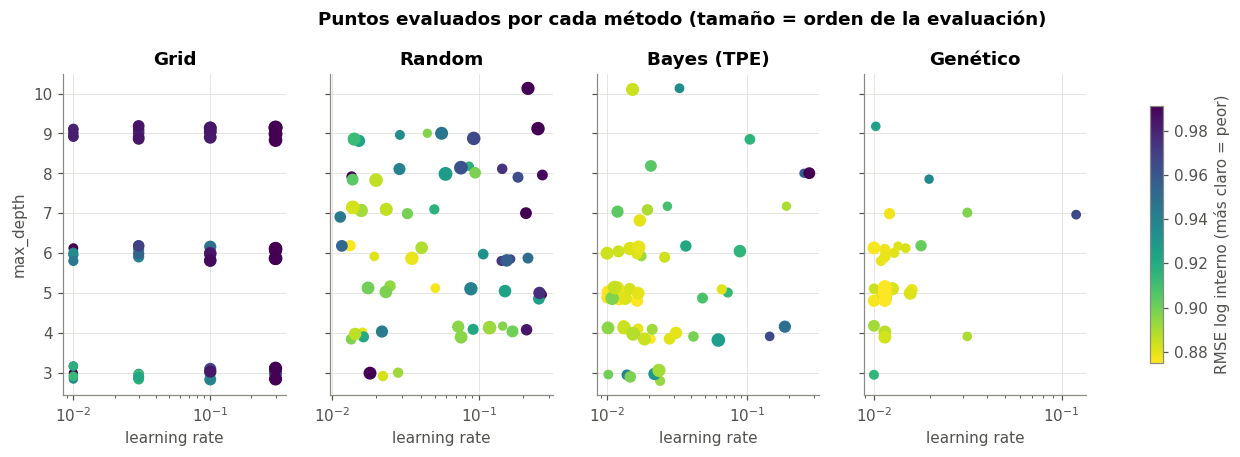

In [11]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
h = hist[(hist["tarea"] == "reg") & (hist["semilla"] == SEED)]
vmin, vmax = h["perdida"].quantile(0.02), h["perdida"].quantile(0.9)
for i, o in enumerate(["grid", "random", "bayes", "genetico"]):
    g = h[h["metodo"] == o]
    lr = g["params"].map(lambda p: p["learning_rate"]); md = g["params"].map(lambda p: p["max_depth"])
    sc = ax[i].scatter(lr, md + np.random.default_rng(1).uniform(-0.2, 0.2, len(g)), c=g["perdida"], cmap="viridis_r",
                       vmin=vmin, vmax=vmax, s=25 + 40 * (g["eval"] / 60))
    ax[i].set_xscale("log"); ax[i].set_title(NOMBRE[o]); ax[i].set_xlabel("learning rate")
ax[0].set_ylabel("max_depth")
fig.colorbar(sc, ax=ax, shrink=0.8, label="RMSE log interno (más claro = peor)")
plt.suptitle("Puntos evaluados por cada método (tamaño = orden de la evaluación)", fontweight="bold", y=1.03)

### Interpretación

- **Grid:** puntos en una retícula fija. Un tercio del presupuesto se gasta en profundidad 9 y un cuarto en *learning rate* 0,3, zonas malas (oscuras) que la rejilla visita igual que las buenas.
- **Random:** cubre todo el plano de forma pareja. Encuentra la zona buena (abajo a la izquierda: *learning rate* bajo, profundidad 4–6) pero sigue gastando evaluaciones en zonas malas hasta el final.
- **Bayes (TPE):** después de unos puntos dispersos (los 5 iniciales al azar y alguna exploración posterior), **concentra las evaluaciones en la zona buena**. Los puntos grandes (evaluaciones tardías) están casi todos en *learning rate* 0,01–0,03 y profundidad 4–6, y son los más claros. Es el balance entre explorar y explotar que da la mejora esperada.
- **Genético:** concentra las evaluaciones **todavía más** en una zona pequeña (*learning rate* ≈ 0,01, profundidad 4–6). Explota mucho y explora poco. Funciona aquí porque la zona es buena, pero es la señal de la convergencia prematura que se ve abajo.

## 🧬 10.5 Diversidad genética

La **diversidad** de una generación es la distancia euclidiana media entre los genomas (en $[0, 1]^6$) de sus individuos. Si cae a casi 0 en pocas generaciones, la población se copió a sí misma: **convergencia prematura**, y el algoritmo deja de explorar.

,tarea,semilla,inicial,final,generaciones,caída (%)
0,reg,42,0.98,0.00,18,99.66
1,reg,7,1.02,0.00,16,100.00
2,reg,2026,0.92,0.00,17,100.00
3,clf,42,0.98,0.00,18,100.00
4,clf,7,1.02,0.00,16,100.00
5,clf,2026,0.92,0.00,17,100.00


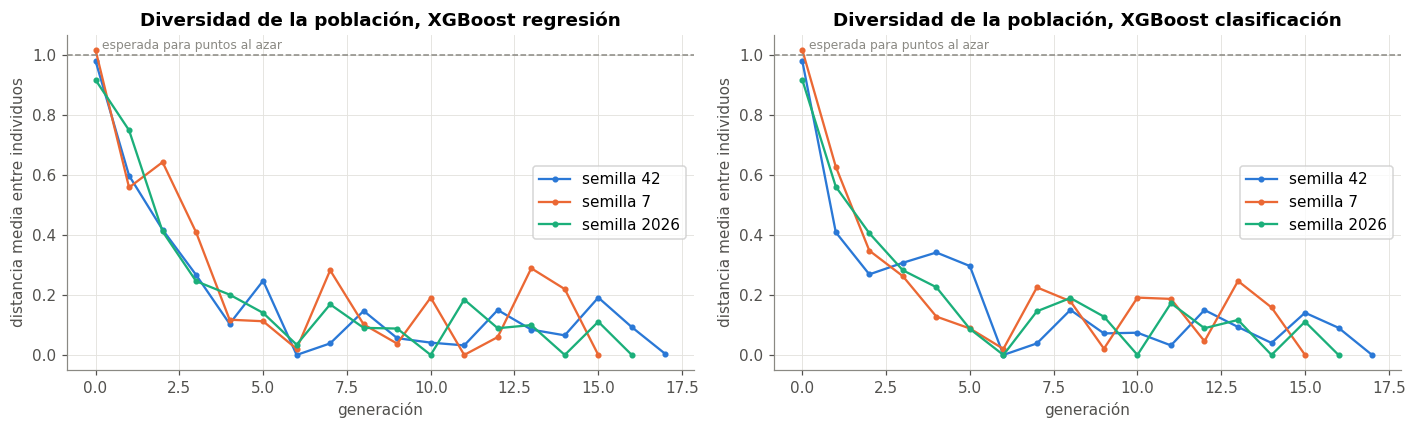

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for c in estudio["corridas"]:
    if c["metodo"] != "genetico":
        continue
    i = 0 if c["tarea"] == "reg" else 1
    ax[i].plot(range(len(c["diversidad"])), c["diversidad"], marker="o", ms=3,
               label=f"semilla {c['semilla']}", color=PALETA[[42, 7, 2026].index(c["semilla"])])
for i, t in enumerate(["regresión", "clasificación"]):
    ax[i].set_xlabel("generación"); ax[i].set_ylabel("distancia media entre individuos")
    ax[i].set_title(f"Diversidad de la población, XGBoost {t}"); ax[i].legend()
    ax[i].axhline(np.sqrt(6 / 6), color=GRIS, ls="--", lw=1)
    ax[i].text(0.2, np.sqrt(6 / 6) + 0.02, "esperada para puntos al azar", fontsize=8, color=GRIS)
plt.tight_layout()
div = pd.DataFrame([{"tarea": c["tarea"], "semilla": c["semilla"], "inicial": c["diversidad"][0],
                     "final": c["diversidad"][-1], "generaciones": len(c["diversidad"])}
                    for c in estudio["corridas"] if c["metodo"] == "genetico"])
div["caída (%)"] = (1 - div["final"] / div["inicial"]) * 100
div.round(3)

### Interpretación

- **La diversidad cae a 0 en las 6 corridas.** Empieza en ~1 (lo esperado para puntos al azar en $[0,1]^6$) y en 16–18 generaciones toda la población es copia del mismo individuo. Es **convergencia prematura**.
- Las causas son el diseño que impuso el presupuesto: **población de 6** con **elitismo** y **torneo de 3**. Con 6 individuos, un torneo de 3 elige casi siempre al mejor o al segundo, y el cruce de dos padres iguales da un hijo igual. La mutación ($\sigma = 0{,}15$, probabilidad 0,3) no alcanza a reponer la diversidad.
- **Consecuencia práctica:** después de ~10 generaciones el genético deja de explorar y repite evaluaciones casi idénticas. Explica por qué en 60 evaluaciones no supera al TPE. **Para usarlo bien** haría falta una población de 20–50 (con presupuestos de cientos de evaluaciones), menor presión de selección (torneo de 2), más mutación o mecanismos de nicho (*fitness sharing*). Con presupuestos de decenas de evaluaciones, **el TPE es la mejor opción**.

## ✂️ 10.6 Multi-fidelidad: Successive Halving

`HalvingRandomSearchCV` con las **mismas 60 configuraciones al azar** que una búsqueda aleatoria completa. La fidelidad es el **número de árboles** de XGBoost: la ronda 1 evalúa las 60 configuraciones con 20 árboles, se queda con el mejor tercio ($\eta = 3$) y le da 60 árboles, después 180 y al final 540. La búsqueda aleatoria completa entrena las 60 con 540 árboles.

**Por qué el número de árboles como fidelidad:** el costo de XGBoost crece lineal con los árboles (cap. 11) y una configuración mala (*learning rate* muy bajo, profundidad inadecuada) ya se ve mala con pocos árboles. **Por qué $\eta = 3$:** es el valor recomendado por Jamieson y Talwalkar (2016) y Li et al. (2018); con 60 candidatos da 4 rondas (60 → 20 → 7 → 3), así que cada configuración que sobrevive recibe 27 veces el presupuesto inicial.

In [13]:
filas = []
for tarea, res in estudio["halving"].items():
    for metodo, r in res.items():
        filas.append({"tarea": tarea, "método": metodo, "minutos": r["seg"] / 60, "árboles entrenados": r["arboles_totales"],
                      "mejor interno": -r["mejor_interno"] if tarea == "reg" else r["mejor_interno"],
                      "pérdida validación externa": r["perdida_externa"],
                      "candidatos por ronda": r["rondas"]})
halving = pd.DataFrame(filas).set_index(["tarea", "método"])
halving["ahorro de tiempo"] = halving["minutos"].groupby(level=0).transform(lambda s: 1 - s.min() / s.max())
halving.round(4)

minutos  árboles entrenados  mejor interno  \
tarea método                                                        
reg   halving             0.42               15840           0.94   
      random completo     1.65               97200           0.88   
clf   halving             0.56               15840           0.33   
      random completo     1.43               97200           0.34   

                       pérdida validación externa        candidatos por ronda  \
tarea método                                                                    
reg   halving                                0.80  {0: 60, 1: 20, 2: 7, 3: 3}   
      random completo                        0.79                        None   
clf   halving                                0.71  {0: 60, 1: 20, 2: 7, 3: 3}   
      random completo                        0.67                        None   

                       ahorro de tiempo  
tarea método                             
reg   halving                      0.74  
      random completo              0.74  
clf   halving                      0.61  
      random completo              0.61

### Interpretación

- **Successive Halving entrena 6 veces menos árboles** (15 840 contra 97 200) y **ahorra 74 % del tiempo en regresión y 61 % en clasificación**.
- **En regresión la calidad casi no cambia**: pérdida en la validación externa de 0,80 contra 0,79. El número de árboles es una buena fidelidad aquí: las configuraciones malas ya son malas con 20 árboles y se descartan pronto.
- **En clasificación pierde algo** (0,71 contra 0,67 en 1 − F1). El F1 con pocos árboles es una señal ruidosa: depende de cuántos casos pasan el umbral de 0,5, y eso cambia mucho entre 20 y 540 árboles. Algunas configuraciones buenas se eliminaron en la primera ronda. **La fidelidad funciona bien cuando el orden de las configuraciones con poco presupuesto se parece al orden con todo el presupuesto**, y eso pasa más con una pérdida continua (RMSE log) que con una métrica umbralizada (F1).
- **Mejora posible:** usar una métrica continua (*log-loss* o AUC) para las rondas tempranas o empezar con más árboles (`min_resources` mayor).